# Loan Default Risk - EDA and Preprocessing (Part A)

**Synthetic educational dataset - not real borrower data.**

In this notebook I:
1. inspect the data (shape, types, missing values, duplicates, statistics)
2. make visualizations
3. build the preprocessing pipeline and a stratified split
4. write down my findings and fairness concerns

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # so we can import from src/

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_preprocessing as dp

sns.set_style("whitegrid")
df = dp.load_data()
df.head()

,ApplicantID,Age,EmploymentType,AnnualIncome,EmploymentYears,LoanAmount,LoanTermMonths,InterestRatePct,CreditScore,ExistingLoans,PastDelinquencies,DebtToIncomeRatio,LoanPurpose,HomeOwnership,Region,BankRelationship,PaymentHistory,Default
0,APP000001,63,Salaried,70138.0,10,862093,48,18.89,685.0,0,0,0.462,Medical,Rent,North,7+ years,Good,No
1,APP000002,29,Contract,93015.0,11,326524,60,12.59,673.0,2,0,0.474,Vehicle,Rent,South,1-3 years,Poor,No
2,APP000003,22,Salaried,92284.0,4,577405,60,17.79,727.0,3,0,0.041,Medical,Own,Central,3-7 years,Good,No
3,APP000004,52,Contract,58718.0,27,617918,60,9.51,686.0,0,0,0.088,Personal,Own,West,3-7 years,Poor,No
4,APP000005,39,Contract,67659.0,8,269636,48,12.25,692.0,0,0,0.110,Medical,Family,East,3-7 years,Fair,Yes


## 1. Inspect the data

In [2]:
print("Shape:", df.shape)
print()
print(df.dtypes)

Shape: (2200, 18)

ApplicantID              str
Age                    int64
EmploymentType           str
AnnualIncome         float64
EmploymentYears        int64
LoanAmount             int64
LoanTermMonths         int64
InterestRatePct      float64
CreditScore          float64
ExistingLoans          int64
PastDelinquencies      int64
DebtToIncomeRatio    float64
LoanPurpose              str
HomeOwnership            str
Region                   str
BankRelationship         str
PaymentHistory           str
Default                  str
dtype: object


In [3]:
# missing values
missing = df.isna().sum()
missing[missing > 0]

AnnualIncome         22
CreditScore          18
DebtToIncomeRatio    20
PaymentHistory       15
dtype: int64

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate ApplicantIDs:", df["ApplicantID"].duplicated().sum())

Duplicate rows: 0
Duplicate ApplicantIDs: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2200.0,45.781818,14.392776,21.00,33.000,46.000,58.0000,70.00
AnnualIncome,2178.0,77193.511938,44745.750247,12000.00,46377.000,67298.500,96164.2500,400000.00
EmploymentYears,2200.0,14.211818,9.455895,0.00,6.000,13.000,21.0000,35.00
LoanAmount,2200.0,426457.250909,282035.979826,29534.00,225610.500,359323.500,542585.0000,2500000.00
LoanTermMonths,2200.0,50.580000,18.323701,12.00,36.000,60.000,60.0000,84.00
InterestRatePct,2200.0,13.498900,3.000619,5.00,11.370,13.460,15.4725,24.50
CreditScore,2182.0,678.832264,63.982655,442.00,635.250,680.000,722.0000,850.00
ExistingLoans,2200.0,1.076364,1.009993,0.00,0.000,1.000,2.0000,6.00
PastDelinquencies,2200.0,0.448636,0.673745,0.00,0.000,0.000,1.0000,4.00
DebtToIncomeRatio,2180.0,0.321167,0.127548,0.03,0.235,0.319,0.4050,0.83


In [6]:
# categorical columns
for col in dp.CATEGORICAL_COLUMNS:
    print(col, df[col].value_counts(dropna=False).to_dict())

EmploymentType {'Salaried': 1208, 'Self-employed': 493, 'Contract': 317, 'Unemployed': 182}
LoanPurpose {'Vehicle': 386, 'Personal': 377, 'Education': 372, 'Home Improvement': 365, 'Medical': 353, 'Business': 347}
HomeOwnership {'Rent': 978, 'Mortgage': 497, 'Own': 428, 'Family': 297}
Region {'Central': 463, 'North': 447, 'West': 442, 'South': 428, 'East': 420}
BankRelationship {'1-3 years': 696, '3-7 years': 579, 'New': 569, '7+ years': 356}
PaymentHistory {'Good': 814, 'Fair': 656, 'Excellent': 407, 'Poor': 308, nan: 15}


**Observations:** 2,200 rows and 18 columns. Four columns have a few missing values (AnnualIncome, CreditScore, DebtToIncomeRatio, PaymentHistory) - less than 1% each. There are no duplicates. `ApplicantID` is just an ID so we drop it. Income and loan amount are right-skewed (a few very big values).

## 2. Visualizations

### Plot 1 - Target balance

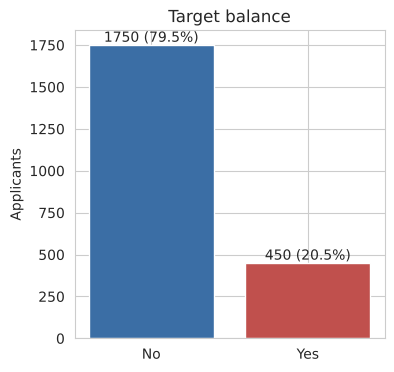

In [7]:
df["DefaultFlag"] = (df["Default"] == "Yes").astype(int)   # 1 = default

counts = df["Default"].value_counts()
plt.figure(figsize=(4, 4))
plt.bar(counts.index, counts.values, color=["#3b6ea5", "#c0504d"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 20, f"{v} ({v/len(df):.1%})", ha="center")
plt.title("Target balance")
plt.ylabel("Applicants")
plt.show()

The data is **imbalanced**: only about 20% of applicants default. A model that always says 'No' would be 80% accurate but useless, so I will use precision, recall, F1, ROC-AUC and PR-AUC instead of accuracy alone.

### Plot 2 - Credit score vs default

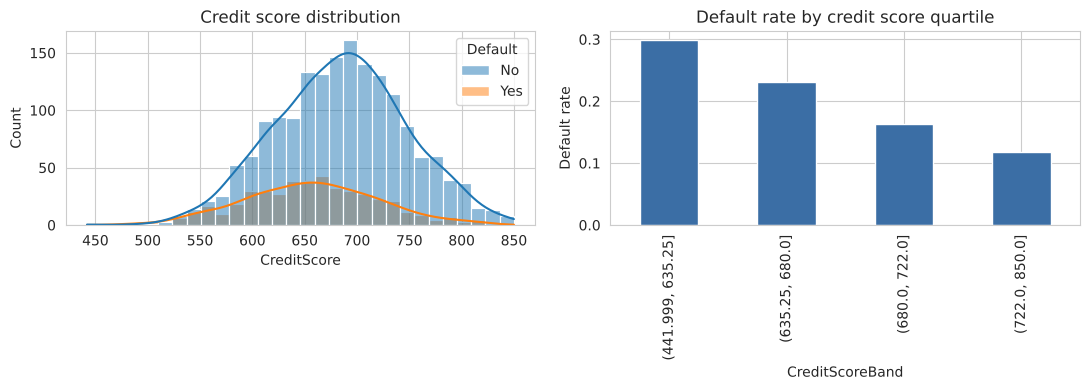

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="CreditScore", hue="Default", bins=30, kde=True, ax=ax[0])
ax[0].set_title("Credit score distribution")

df["CreditScoreBand"] = pd.qcut(df["CreditScore"], 4)
df.groupby("CreditScoreBand", observed=True)["DefaultFlag"].mean().plot(kind="bar", ax=ax[1], color="#3b6ea5")
ax[1].set_title("Default rate by credit score quartile")
ax[1].set_ylabel("Default rate")
plt.tight_layout()
plt.show()

The default rate drops steadily as credit score goes up (about 30% in the lowest quartile vs about 12% in the highest). Credit score looks like the strongest single signal.

### Plot 3 - Default rate by employment type

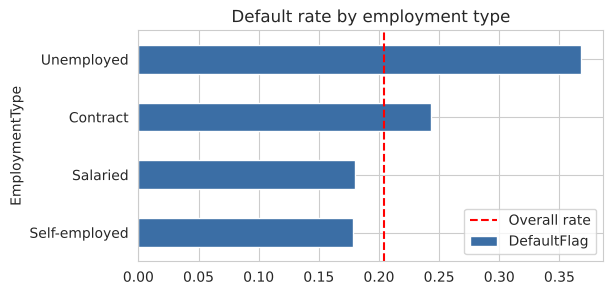

In [9]:
rates = df.groupby("EmploymentType")["DefaultFlag"].mean().sort_values()
rates.plot(kind="barh", color="#3b6ea5", figsize=(6, 3))
plt.axvline(df["DefaultFlag"].mean(), color="red", linestyle="--", label="Overall rate")
plt.legend()
plt.title("Default rate by employment type")
plt.show()

Unemployed applicants default most (about 37%), then Contract (about 24%). Salaried and Self-employed are near 18%.

### Plot 4 - Debt-to-income ratio and delinquencies

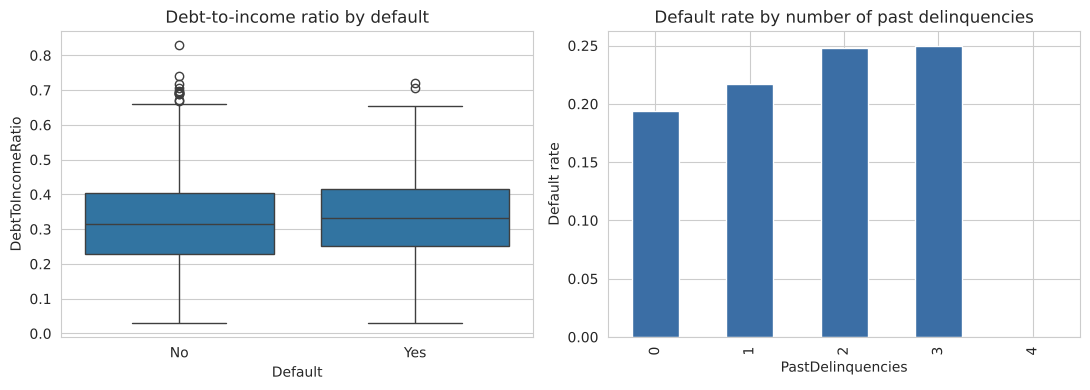

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="Default", y="DebtToIncomeRatio", ax=ax[0])
ax[0].set_title("Debt-to-income ratio by default")

df.groupby("PastDelinquencies")["DefaultFlag"].mean().plot(kind="bar", ax=ax[1], color="#3b6ea5")
ax[1].set_title("Default rate by number of past delinquencies")
ax[1].set_ylabel("Default rate")
plt.tight_layout()
plt.show()

Defaulters have a slightly higher debt-to-income ratio. The default rate rises a little with more delinquencies (the 4-delinquency bar has only 3 people, so ignore it).

### Plot 5 - Correlation heatmap (numeric features)

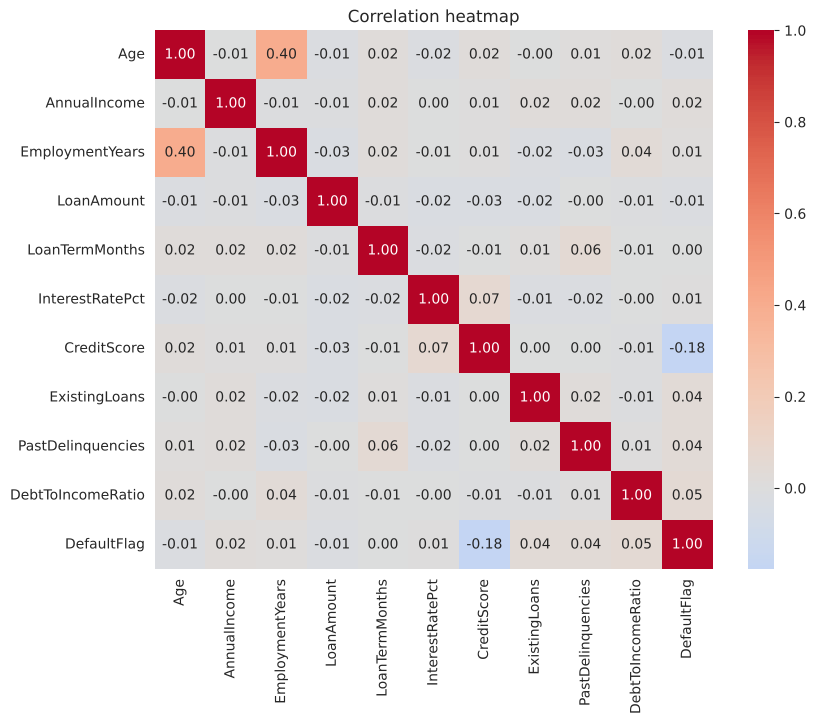

In [11]:
num_cols = dp.NUMERIC_COLUMNS + ["DefaultFlag"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

All correlations with the target are small. CreditScore is the strongest (about -0.18). Features are not strongly correlated with each other, so there is no big multicollinearity problem.

### Plot 6 - Payment history and region

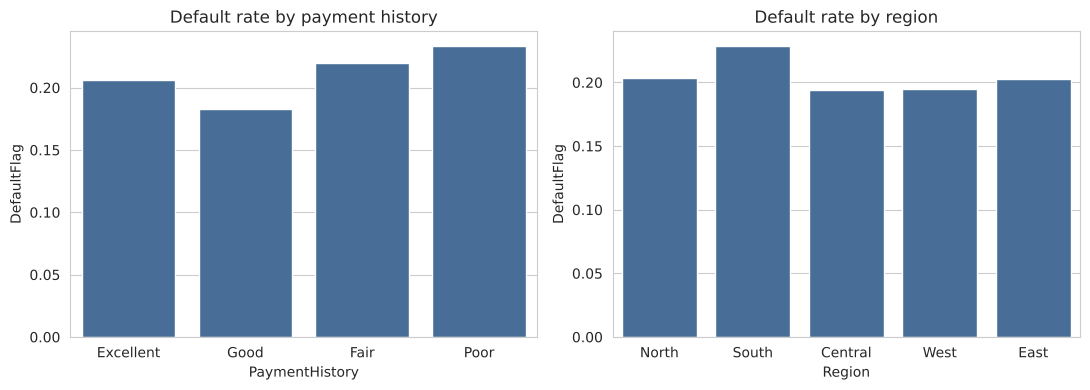

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ["Excellent", "Good", "Fair", "Poor"]
sns.barplot(data=df, x="PaymentHistory", y="DefaultFlag", order=order, errorbar=None, ax=ax[0], color="#3b6ea5")
ax[0].set_title("Default rate by payment history")
sns.barplot(data=df, x="Region", y="DefaultFlag", errorbar=None, ax=ax[1], color="#3b6ea5")
ax[1].set_title("Default rate by region")
plt.tight_layout()
plt.show()

Strange: 'Excellent' payment history does not have a lower default rate than 'Good'. In real life I would expect a clear order. Since the data is synthetic the label may be only loosely tied to this column. Region barely matters (all around 19-23%).

### Plot 7 - Income and loan amount (skew)

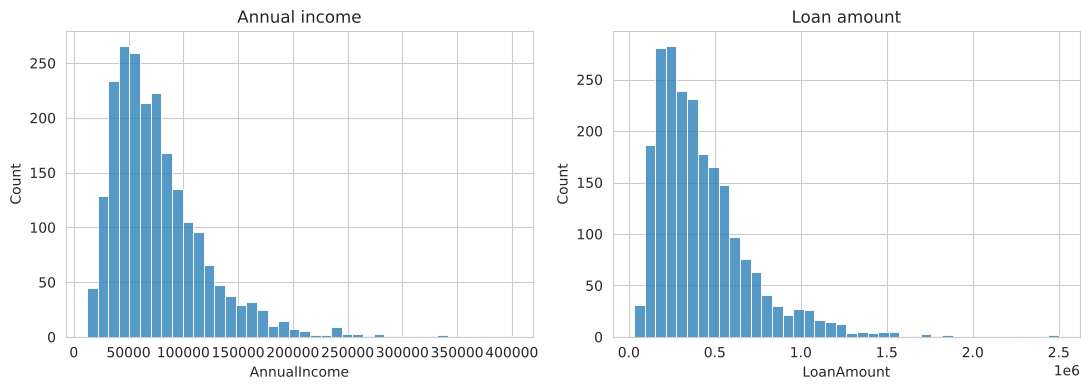

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["AnnualIncome"].dropna(), bins=40, ax=ax[0])
ax[0].set_title("Annual income")
sns.histplot(df["LoanAmount"], bins=40, ax=ax[1])
ax[1].set_title("Loan amount")
plt.tight_layout()
plt.show()

## 3. Summary of findings

1. **Imbalanced target** - about 20.5% defaults, so accuracy is misleading.
2. **Credit score is the clearest signal** - default rate falls from about 30% (lowest quartile) to about 12% (highest quartile).
3. **Employment type matters** - Unemployed (about 37%) and Contract (about 24%) default more than Salaried/Self-employed (about 18%).
4. **Most other features are weak** - correlations with the target are all small (below 0.06 apart from credit score), so I expect a modest model (ROC-AUC well below 0.8).
5. **PaymentHistory is not ordered as expected** - 'Excellent' is not better than 'Good'.

## Bias and fairness concerns

- **Age** is a feature. Using age in real lending can be age discrimination and is restricted in many places.
- **Region** could act as a proxy for community, ethnicity or income level. Default rates differ a little (South 22.9% vs Central 19.4%), and a model could unfairly penalise a region.
- **EmploymentType = Unemployed** gets a high risk score, which could lock out people who are able to repay (for example, someone living on savings or family support).
- **HomeOwnership** and **BankRelationship** may favour already advantaged people.
- The label is **simulated**, so the model learns the simulation's rules, not real borrower behaviour.
- Before any real use we would need fairness checks (compare approval and error rates across groups), legal review, and removal or careful treatment of sensitive features.

## 4. Preprocessing and stratified split

In [14]:
X, y = dp.get_X_y(df.drop(columns=["DefaultFlag", "CreditScoreBand"]))
print("Features used:", list(X.columns))
print("ApplicantID in features?", "ApplicantID" in X.columns)

X_train, X_test, y_train, y_test = dp.split_data(X, y)
print()
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Default rate in train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))

Features used: ['Age', 'AnnualIncome', 'EmploymentYears', 'LoanAmount', 'LoanTermMonths', 'InterestRatePct', 'CreditScore', 'ExistingLoans', 'PastDelinquencies', 'DebtToIncomeRatio', 'EmploymentType', 'LoanPurpose', 'HomeOwnership', 'Region', 'BankRelationship', 'PaymentHistory']
ApplicantID in features? False

Train: (1760, 16)  Test: (440, 16)
Default rate in train: 0.205   test: 0.205


The stratified split keeps the default rate the same in train and test.

In [15]:
# the preprocessor: impute + scale numbers, impute + one-hot categories
preprocessor = dp.build_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [16]:
# fit ONLY on training data, then transform both (this avoids data leakage)
Xt_train = preprocessor.fit_transform(X_train)
Xt_test = preprocessor.transform(X_test)
print("Columns before:", X_train.shape[1], "-> after preprocessing:", Xt_train.shape[1])
print("NaN left in transformed train data:", np.isnan(Xt_train).sum())

Columns before: 16 -> after preprocessing: 37
NaN left in transformed train data: 0


**Why a Pipeline + ColumnTransformer?** The imputer medians and scaler means come from the training set only. When the preprocessing is inside the same Pipeline as the model, cross-validation re-fits it on each training fold, so nothing from the validation fold leaks in.